## 1. Setup: the feature store

In [1]:
%load_ext autoreload
%autoreload 2

import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from aml.api import load_reference
from aml.config import Config
from aml.pipeline import run_build_store, run_drift_report
from aml.plotting import LAUNDERING, MUTED, NORMAL, save, set_style
from aml.serving import DriftMonitor, Scorer

config = Config()
paths = config.paths
FIG = paths.figures_dir
PROC = paths.processed_dir

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [2]:
store_path = PROC / "feature_store.pkl"
if not store_path.exists():
    run_build_store(config)                 # about 10 seconds; same as `python main.py build-store`
scorer = Scorer.load(store_path, config)
store = scorer.store
print(f"{len(store.node_index):,} accounts | history {store.origin:%Y-%m-%d} "
      f"to {store.history_end} | answers up to {store.horizon_end} | "
      f"{store_path.stat().st_size / 1e6:,.0f} MB on disk")
print(f"Served model threshold: {scorer.threshold:.4f} (flags {scorer.budget:.0%} of normal validation payments)")

515,078 accounts | history 2022-09-01 to 2022-09-10 23:59:00 | answers up to 2022-10-10 23:59:00 | 616 MB on disk
Served model threshold: 0.0175 (flags 1% of normal validation payments)


## 2. Live features equal batch features


In [3]:
tx = pd.read_parquet(PROC / "transactions.parquet")
test = tx[tx["split"] == "test"]
rng = np.random.default_rng(0)
sample = pd.concat([test.sample(3000, random_state=0), test[test["is_laundering"] == 1].sample(200, random_state=0)])


def to_raw(rows: pd.DataFrame) -> pd.DataFrame:
    """Payments as they arrive: the raw dataset's fields, nothing derived."""
    return pd.DataFrame({
        "timestamp": rows["timestamp"], "from_bank": rows["from_bank"], "from_account": rows["from_account"],
        "to_bank": rows["to_bank"], "to_account": rows["to_account"], "amount_paid": rows["amount_paid"],
        "payment_currency": rows["pay_currency"].astype(str), "amount_received": rows["amount_received"],
        "receiving_currency": rows["recv_currency"].astype(str), "payment_format": rows["payment_format"].astype(str),
    }).reset_index(drop=True)


raw = to_raw(sample)
live = store.transform(store.prepare(raw))
graph_cols = json.loads((PROC / "graph_feature_list.json").read_text())["features"]
batch = pd.concat([
    pd.read_parquet(PROC / "features.parquet").loc[sample.index].reset_index(drop=True),
    pd.read_parquet(PROC / "graph_features.parquet", columns=graph_cols).loc[sample.index].reset_index(drop=True),
], axis=1)[store.features]
pd.testing.assert_frame_equal(live, batch, check_dtype=False)

scored = scorer.score(raw)
batch_scores = pd.read_parquet(PROC / "graph_scores.parquet").set_index("tx_id").loc[sample["tx_id"], "score"]
max_gap = float(np.abs(scored["score"].to_numpy() - batch_scores.to_numpy()).max())
print(f"{len(raw):,} payments: all {live.shape[1]} features identical to the batch tables; "
      f"largest score difference {max_gap:.2e}")

3,200 payments: all 95 features identical to the batch tables; largest score difference 0.00e+00


## 3. Scoring payments, with reasons




In [4]:
examples = pd.concat([test[test["is_laundering"] == 1].head(3), test[test["is_laundering"] == 0].head(2)])
raw_examples = to_raw(examples)
new_accounts = raw_examples.iloc[[0]].assign(from_account="NEW-ACCOUNT-1", to_account="NEW-ACCOUNT-2")
raw_examples = pd.concat([raw_examples, new_accounts], ignore_index=True)
out = scorer.score(raw_examples)
out.insert(0, "actually_laundering", list(examples["is_laundering"]) + ["unknown (made up)"])
out.insert(1, "format", raw_examples["payment_format"])
out

,actually_laundering,format,score,alert,top_features,known_sender,known_receiver
0,1,ACH,0.6285,True,"[payment_format_code, log_amount_usd, pair_pri...",True,True
1,1,ACH,0.5698,True,"[payment_format_code, pair_prior_cnt, snd_enti...",True,True
2,1,ACH,0.8290,True,"[payment_format_code, snd_self_cnt_all, pair_p...",True,True
3,0,Cheque,0.0059,False,"[snd_out_cnt_1h, snd_out_distinct_cp_all, rcv_...",True,True
4,0,Wire,0.0000,False,"[snd_in_distinct_cp_all, snd_entity_n_accounts...",True,True
5,unknown (made up),ACH,0.0324,True,"[payment_format_code, log_amount_usd, pair_pri...",False,False


## 4. Latency


In [5]:
one = raw.iloc[[0]]
scorer.score(one)                                         # warm the day's snapshot
timings = []
for i in range(50):
    t0 = time.perf_counter()
    scorer.score(raw.iloc[[i]])
    timings.append((time.perf_counter() - t0) * 1000)
t0 = time.perf_counter()
scorer.score(raw)
batch_ms = (time.perf_counter() - t0) * 1000
print(f"One payment: median {np.median(timings):.0f} ms (p95 {np.percentile(timings, 95):.0f} ms); "
      f"a batch of {len(raw):,}: {batch_ms / len(raw):.2f} ms per payment")

One payment: median 41 ms (p95 55 ms); a batch of 3,200: 0.34 ms per payment


## 5. Drift: what the monitor would have reported



In [6]:
drift = run_drift_report(config)
drift[["split", "payments", "alert_rate", "expected_alert_rate", "fpr", "score_psi_vs_val",
       "most_shifted_feature", "max_feature_psi", "status"]]

18:52:13 | INFO | aml.pipeline | Daily drift report (served model, threshold 0.0175):
               split  payments  alert_rate    fpr  score_psi_vs_val  max_feature_psi most_shifted_feature status
day                                                                                                             
2022-09-06       val    202735      0.0116 0.0107            0.0015           5.6021   snd_component_size     ok
2022-09-07       val    482751      0.0107 0.0099            0.0001           5.6174   snd_component_size     ok
2022-09-08  test/val    482773      0.0109 0.0100            0.0036           5.6279   snd_component_size     ok
2022-09-09      test    654467      0.0110 0.0104            0.0756           5.6180   snd_component_size     ok
2022-09-10      test    208325      0.0241 0.0222            0.0091           5.6068   snd_component_size  drift


,split,payments,alert_rate,expected_alert_rate,fpr,score_psi_vs_val,most_shifted_feature,max_feature_psi,status
day,,,,,,,,,
2022-09-06,val,202735,0.0116,0.0109,0.0107,0.0015,snd_component_size,5.6021,ok
2022-09-07,val,482751,0.0107,0.0109,0.0099,0.0001,snd_component_size,5.6174,ok
2022-09-08,test/val,482773,0.0109,0.0109,0.0100,0.0036,snd_component_size,5.6279,ok
2022-09-09,test,654467,0.0110,0.0109,0.0104,0.0756,snd_component_size,5.6180,ok
2022-09-10,test,208325,0.0241,0.0109,0.0222,0.0091,snd_component_size,5.6068,drift


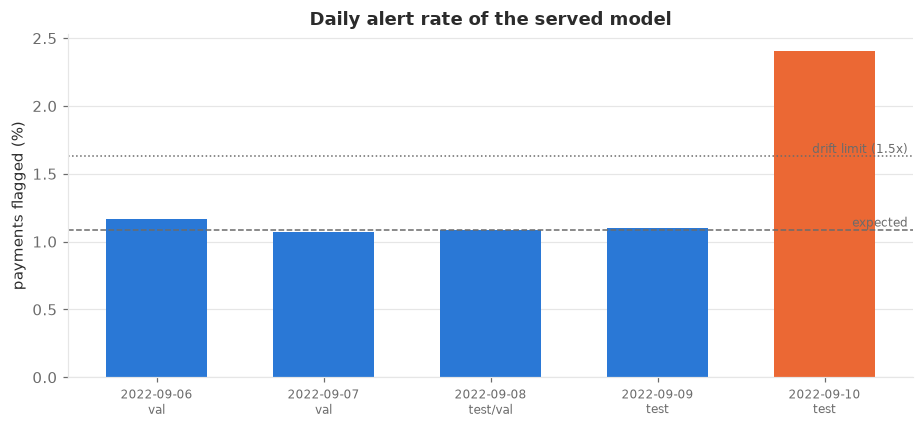

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 4))
x = np.arange(len(drift))
colors = [LAUNDERING if s == "drift" else NORMAL for s in drift["status"]]
ax.bar(x, drift["alert_rate"] * 100, color=colors, width=0.6)
ax.axhline(drift["expected_alert_rate"].iloc[0] * 100, color=MUTED, linestyle="--", linewidth=1)
ax.axhline(drift["expected_alert_rate"].iloc[0] * 150, color=MUTED, linestyle=":", linewidth=1)
ax.text(len(drift) - 0.5, drift["expected_alert_rate"].iloc[0] * 100, "expected", va="bottom", ha="right",
        fontsize=8, color=MUTED)
ax.text(len(drift) - 0.5, drift["expected_alert_rate"].iloc[0] * 150, "drift limit (1.5x)", va="bottom",
        ha="right", fontsize=8, color=MUTED)
ax.set_xticks(x, [f"{d}\n{s}" for d, s in zip(drift.index, drift["split"])], fontsize=8)
ax.set_ylabel("payments flagged (%)")
ax.set_title("Daily alert rate of the served model")
ax.grid(axis="x", visible=False)
plt.tight_layout()
save(fig, FIG, "15_daily_alert_rate")
plt.show()

In [8]:
psi_cols = [c for c in drift.columns if c.startswith("psi_")]
feature_psi = drift[psi_cols].T
feature_psi.index = feature_psi.index.str.removeprefix("psi_")
feature_psi.sort_values(feature_psi.columns[-1], ascending=False)

day,2022-09-06,2022-09-07,2022-09-08,2022-09-09,2022-09-10
snd_component_size,5.6021,5.6174,5.6279,5.6180,5.6068
pair_prior_cnt,2.6090,2.4737,3.1033,1.6492,3.2811
rcv_in_distinct_cp_all,1.0639,1.0356,1.0693,1.0516,1.0519
snd_out_distinct_cp_all,0.7547,0.7421,0.7584,0.8041,0.5537
is_self_loop,0.3563,0.3641,0.3637,0.3771,0.3685
payment_format_code,0.2654,0.2718,0.2718,0.2878,0.2945
same_entity,0.2902,0.2952,0.2947,0.2888,0.2867
log_amount_usd,0.0723,0.0579,0.0573,0.0781,0.0655
snd_out_cnt_1h,0.0646,0.0480,0.0478,0.0121,0.0131
pair_reverse_prior_cnt,0.0000,0.0000,0.0000,0.0000,0.0000


## 6. Replaying the test period through the live monitor



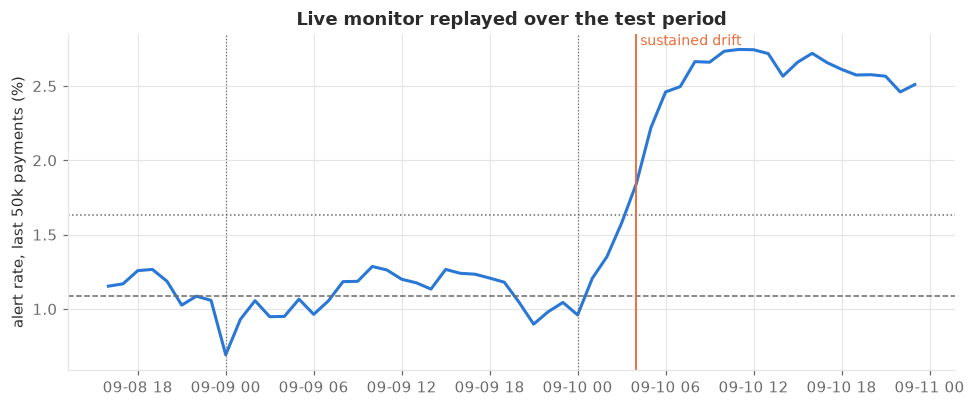

Sustained drift from 2022-09-10 04:00:00
Single-hour flags (dotted lines): ['2022-09-09 00:00:00', '2022-09-10 00:00:00']


,window,alert_rate,alert_rate_ratio,score_psi,sustained
hour,,,,,
2022-09-09 00:00:00,50000,0.0069,0.6360,0.1944,False
2022-09-10 00:00:00,50000,0.0096,0.8823,0.2091,False
2022-09-10 04:00:00,50000,0.0184,1.6929,0.0325,True
2022-09-10 05:00:00,50000,0.0222,2.0403,0.0075,True
2022-09-10 06:00:00,50000,0.0246,2.2609,0.0206,True
2022-09-10 07:00:00,50000,0.0250,2.2940,0.0222,True
2022-09-10 08:00:00,50000,0.0266,2.4484,0.0234,True
2022-09-10 09:00:00,50000,0.0266,2.4447,0.0231,True
2022-09-10 10:00:00,50000,0.0273,2.5127,0.0200,True


In [9]:
graph_scores = pd.read_parquet(PROC / "graph_scores.parquet")
stream = graph_scores[graph_scores["split"] == "test"].merge(tx[["tx_id", "timestamp"]], on="tx_id").sort_values("timestamp")
monitor = DriftMonitor(load_reference(config), scorer.threshold, scorer.budget)
replay = []
for hour, g in stream.groupby(stream["timestamp"].dt.floor("h")):
    monitor.update(g["score"].to_numpy())
    replay.append({"hour": hour, **monitor.report()})
replay = pd.DataFrame(replay).set_index("hour")
is_drift = replay["status"].eq("drift")
sustained = is_drift & is_drift.shift(1, fill_value=False) & is_drift.shift(2, fill_value=False)
first_drift = replay.index[sustained].min() - pd.Timedelta(hours=2) if sustained.any() else pd.NaT
transient = replay.index[is_drift & ~(sustained | sustained.shift(-1, fill_value=False)
                                      | sustained.shift(-2, fill_value=False))]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(replay.index, replay["alert_rate"] * 100, color=NORMAL)
ax.axhline(monitor.expected_rate * 100, color=MUTED, linestyle="--", linewidth=1)
ax.axhline(monitor.expected_rate * 150, color=MUTED, linestyle=":", linewidth=1)
if pd.notna(first_drift):
    ax.axvline(first_drift, color=LAUNDERING, linewidth=1.2)
    ax.text(first_drift, ax.get_ylim()[1], " sustained drift", color=LAUNDERING, va="top", fontsize=9)
for t in transient:
    ax.axvline(t, color=MUTED, linewidth=0.8, linestyle=":")
ax.set_ylabel("alert rate, last 50k payments (%)")
ax.set_title("Live monitor replayed over the test period")
plt.tight_layout()
save(fig, FIG, "16_monitor_replay")
plt.show()
print(f"Sustained drift from {first_drift}" if pd.notna(first_drift) else "No sustained drift")
print(f"Single-hour flags (dotted lines): {[str(t) for t in transient]}")
replay.loc[is_drift, ["window", "alert_rate", "alert_rate_ratio", "score_psi"]].assign(
    sustained=lambda r: r.index >= first_drift if pd.notna(first_drift) else False)

## 7. Findings

In [10]:
d = drift
drift_days = list(d.index[d["status"] == "drift"])
lines = [
    f"- **Live features equal batch features**: {len(raw):,} real test payments sent as raw records get all "
    f"{live.shape[1]} features identical to the batch tables and the same scores (largest difference {max_gap:.1e}).",
    f"- **Fast enough to score in real time**: median {np.median(timings):.0f} ms per payment, "
    f"{batch_ms / len(raw):.2f} ms per payment in batches.",
    f"- **Drift is concentrated on the last day**: the daily alert rate stays near the expected "
    f"{d['expected_alert_rate'].iloc[0]:.2%} until {drift_days[0] if drift_days else 'the end'}, when it reaches "
    f"{d['alert_rate'].max():.2%}; that day the simulation winds down ({int(d['payments'].iloc[-1]):,} payments vs "
    f"{int(d['payments'].iloc[-2]):,} the day before). The step 3 baseline already drifted a day earlier "
    f"(2% of normal payments flagged on 9 September); the served step 4 model holds its budget longer.",
    (f"- **The live monitor would have caught it**: replaying the test period, drift is sustained from "
     f"{first_drift:%Y-%m-%d %H:%M}; {len(transient)} single-hour flags at midnight bursts of scheduled payments "
     f"are filtered out by requiring three consecutive hours." if pd.notna(first_drift)
     else "- **The live monitor never flags sustained drift** on the test period."),
    "- **One feature trends by construction**: `snd_component_size` grows with the graph (PSI > 5 against "
    "training on every day); it should be monitored against a recent reference or redefined.",
]
display(Markdown("\n".join(lines)))

- **Live features equal batch features**: 3,200 real test payments sent as raw records get all 95 features identical to the batch tables and the same scores (largest difference 0.0e+00).
- **Fast enough to score in real time**: median 41 ms per payment, 0.34 ms per payment in batches.
- **Drift is concentrated on the last day**: the daily alert rate stays near the expected 1.09% until 2022-09-10, when it reaches 2.41%; that day the simulation winds down (208,325 payments vs 654,467 the day before). The step 3 baseline already drifted a day earlier (2% of normal payments flagged on 9 September); the served step 4 model holds its budget longer.
- **The live monitor would have caught it**: replaying the test period, drift is sustained from 2022-09-10 04:00; 2 single-hour flags at midnight bursts of scheduled payments are filtered out by requiring three consecutive hours.
- **One feature trends by construction**: `snd_component_size` grows with the graph (PSI > 5 against training on every day); it should be monitored against a recent reference or redefined.